In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Location: Delhi, India
latitude = 28.6139
longitude = 77.2090

# Full calendar year
start_date = "2025-01-01"
end_date = "2025-12-31"

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": start_date,
    "end_date": end_date,
    "daily": [
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min",
        "precipitation_sum"
    ],
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=60)

# Raise an error if the API request failed
response.raise_for_status()

weather_json = response.json()

# Convert the daily weather response into a DataFrame
df = pd.DataFrame(weather_json["daily"])

# Rename columns to make them easier to understand
df = df.rename(columns={
    "time": "Date",
    "temperature_2m_mean": "Avg_Temperature",
    "temperature_2m_max": "Max_Temperature",
    "temperature_2m_min": "Min_Temperature",
    "precipitation_sum": "Rainfall"
})

df["Date"] = pd.to_datetime(df["Date"])

# Save the real weather records as CSV
df.to_csv("weather_data_real.csv", index=False)

print("Real weather data downloaded successfully!")
print("Number of records:", len(df))
print("Columns:", df.columns.tolist())

display(df.head())

Real weather data downloaded successfully!
Number of records: 365
Columns: ['Date', 'Avg_Temperature', 'Max_Temperature', 'Min_Temperature', 'Rainfall']


,Date,Avg_Temperature,Max_Temperature,Min_Temperature,Rainfall
0,2025-01-01,11.1,16.8,7.6,0.0
1,2025-01-02,12.4,18.3,8.4,0.0
2,2025-01-03,12.8,19.6,8.6,0.0
3,2025-01-04,13.5,21.2,8.4,0.0
4,2025-01-05,12.4,18.1,9.1,0.0


In [2]:
print("Dataset shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate dates:", df["Date"].duplicated().sum())

Dataset shape: (365, 5)

Column data types:
Date               datetime64[us]
Avg_Temperature           float64
Max_Temperature           float64
Min_Temperature           float64
Rainfall                  float64
dtype: object

Missing values:
Date               0
Avg_Temperature    0
Max_Temperature    0
Min_Temperature    0
Rainfall           0
dtype: int64

Duplicate dates: 0


In [3]:
df = df.drop_duplicates(subset="Date")
df = df.sort_values("Date").reset_index(drop=True)

weather_columns = [
    "Avg_Temperature",
    "Max_Temperature",
    "Min_Temperature",
    "Rainfall"
]

df[weather_columns] = df[weather_columns].apply(
    pd.to_numeric, errors="coerce"
)

df = df.dropna(subset=weather_columns)

print("Cleaned dataset shape:", df.shape)
display(df.head())

Cleaned dataset shape: (365, 5)


,Date,Avg_Temperature,Max_Temperature,Min_Temperature,Rainfall
0,2025-01-01,11.1,16.8,7.6,0.0
1,2025-01-02,12.4,18.3,8.4,0.0
2,2025-01-03,12.8,19.6,8.6,0.0
3,2025-01-04,13.5,21.2,8.4,0.0
4,2025-01-05,12.4,18.1,9.1,0.0


In [4]:
print("WEATHER SUMMARY")
print("=" * 35)

print(
    "Average temperature:",
    round(df["Avg_Temperature"].mean(), 2), "°C"
)

print(
    "Lowest minimum temperature:",
    df["Min_Temperature"].min(), "°C"
)

print(
    "Highest maximum temperature:",
    df["Max_Temperature"].max(), "°C"
)

print(
    "Average daily rainfall:",
    round(df["Rainfall"].mean(), 2), "mm"
)

print(
    "Total recorded precipitation:",
    round(df["Rainfall"].sum(), 2), "mm"
)

print(
    "Days with recorded rainfall:",
    (df["Rainfall"] > 0).sum()
)

WEATHER SUMMARY
Average temperature: 25.25 °C
Lowest minimum temperature: 7.6 °C
Highest maximum temperature: 43.7 °C
Average daily rainfall: 1.96 mm
Total recorded precipitation: 716.0 mm
Days with recorded rainfall: 145


In [5]:
hottest_day = df.loc[df["Max_Temperature"].idxmax()]
wettest_day = df.loc[df["Rainfall"].idxmax()]

print("Hottest day:")
display(hottest_day)

print("Wettest day:")
display(wettest_day)

Hottest day:


Date               2025-06-09 00:00:00
Avg_Temperature                   37.5
Max_Temperature                   43.7
Min_Temperature                   29.8
Rainfall                           0.0
Name: 159, dtype: object

Wettest day:


Date               2025-09-01 00:00:00
Avg_Temperature                   25.4
Max_Temperature                   29.2
Min_Temperature                   24.0
Rainfall                          32.6
Name: 243, dtype: object

In [6]:
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%b")

monthly = df.groupby("Month").agg(
    Avg_Temperature=("Avg_Temperature", "mean"),
    Max_Temperature=("Max_Temperature", "mean"),
    Min_Temperature=("Min_Temperature", "mean"),
    Total_Rainfall=("Rainfall", "sum"),
    Rainy_Days=("Rainfall", lambda x: (x > 0).sum())
).reset_index()

monthly["Month_Name"] = pd.to_datetime(
    monthly["Month"], format="%m"
).dt.strftime("%B")

print("MONTHLY WEATHER ANALYSIS")
display(monthly.round(2))

MONTHLY WEATHER ANALYSIS


,Month,Avg_Temperature,Max_Temperature,Min_Temperature,Total_Rainfall,Rainy_Days,Month_Name
0,1,14.05,20.07,9.28,14.1,7,January
1,2,19.05,24.99,13.51,15.5,8,February
2,3,24.25,30.76,17.68,14.2,5,March
3,4,31.29,38.40,24.11,10.6,3,April
4,5,31.88,37.96,26.14,29.5,15,May
5,6,31.97,36.84,27.04,126.3,21,June
6,7,29.53,33.29,26.30,171.6,28,July
7,8,28.69,31.96,25.90,191.0,28,August
8,9,29.94,34.31,25.68,117.6,19,September
9,10,26.03,31.01,21.50,25.6,11,October


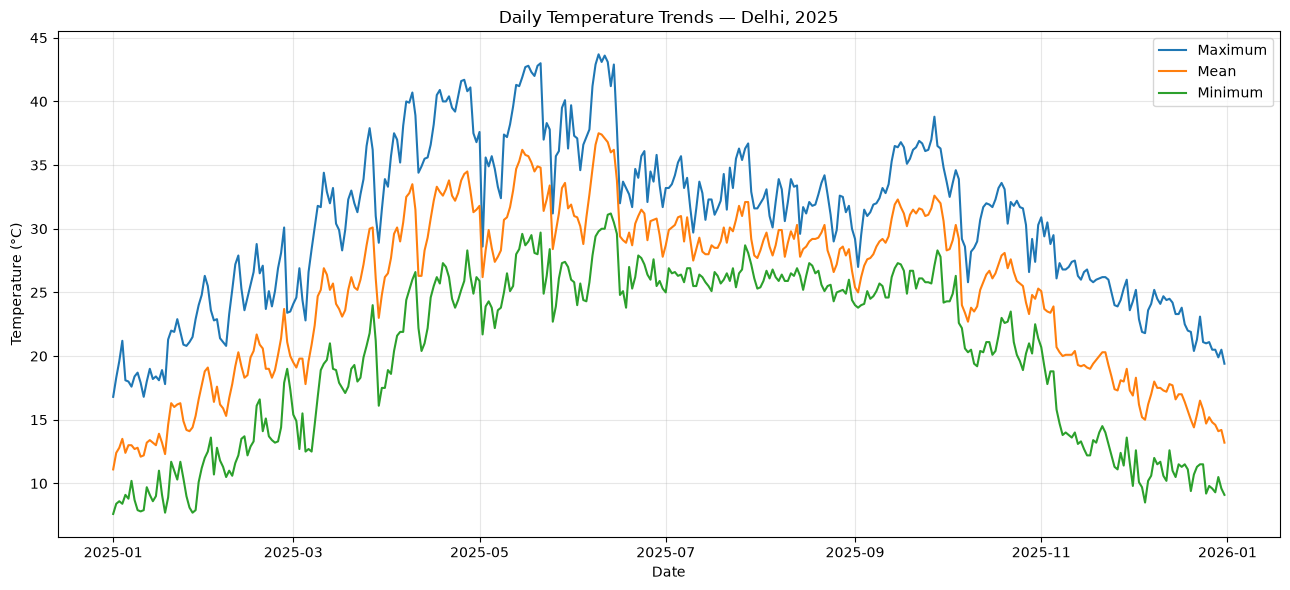

In [7]:
plt.figure(figsize=(13, 6))

plt.plot(
    df["Date"], df["Max_Temperature"],
    label="Maximum", linewidth=1.5
)

plt.plot(
    df["Date"], df["Avg_Temperature"],
    label="Mean", linewidth=1.5
)

plt.plot(
    df["Date"], df["Min_Temperature"],
    label="Minimum", linewidth=1.5
)

plt.title("Daily Temperature Trends — Delhi, 2025")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

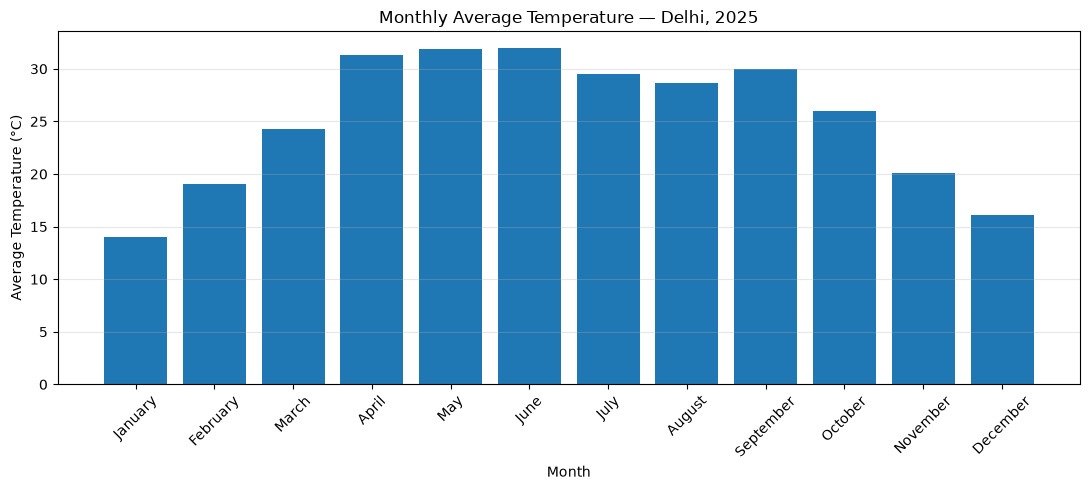

In [8]:
plt.figure(figsize=(11, 5))

plt.bar(
    monthly["Month_Name"],
    monthly["Avg_Temperature"]
)

plt.title("Monthly Average Temperature — Delhi, 2025")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

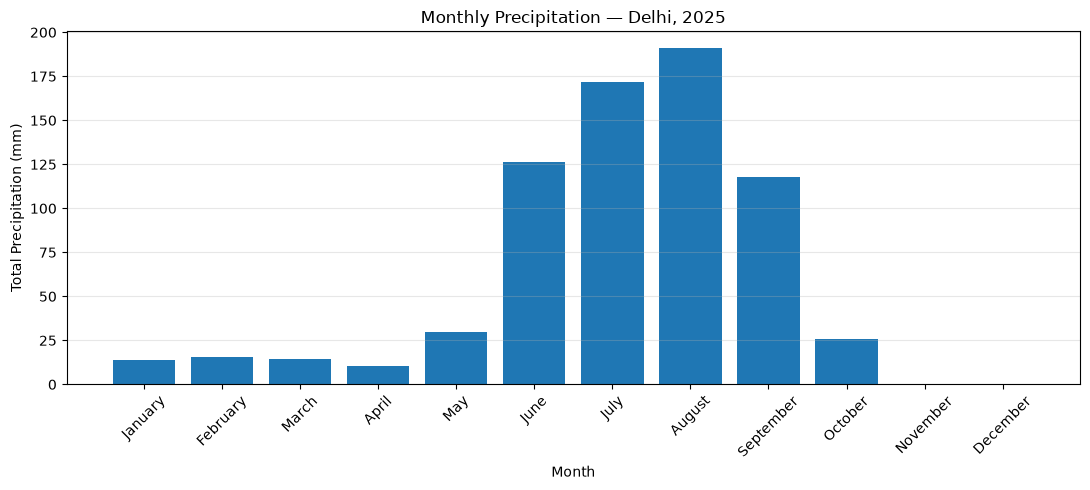

In [9]:
plt.figure(figsize=(11, 5))

plt.bar(
    monthly["Month_Name"],
    monthly["Total_Rainfall"]
)

plt.title("Monthly Precipitation — Delhi, 2025")
plt.xlabel("Month")
plt.ylabel("Total Precipitation (mm)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

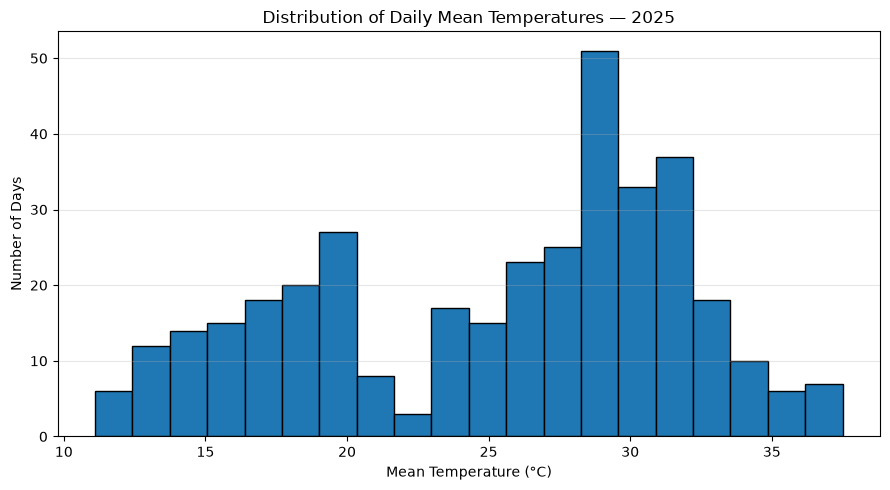

In [10]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Avg_Temperature"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Daily Mean Temperatures — 2025")
plt.xlabel("Mean Temperature (°C)")
plt.ylabel("Number of Days")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
import os

os.makedirs("charts", exist_ok=True)

# Daily temperatures
plt.figure(figsize=(13, 6))
plt.plot(df["Date"], df["Max_Temperature"], label="Maximum")
plt.plot(df["Date"], df["Avg_Temperature"], label="Mean")
plt.plot(df["Date"], df["Min_Temperature"], label="Minimum")
plt.title("Daily Temperature Trends — Delhi, 2025")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("charts/daily_temperature.png", dpi=150)
plt.close()

# Monthly average temperature
plt.figure(figsize=(11, 5))
plt.bar(monthly["Month_Name"], monthly["Avg_Temperature"])
plt.title("Monthly Average Temperature — Delhi, 2025")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("charts/monthly_temperature.png", dpi=150)
plt.close()

# Monthly precipitation
plt.figure(figsize=(11, 5))
plt.bar(monthly["Month_Name"], monthly["Total_Rainfall"])
plt.title("Monthly Precipitation — Delhi, 2025")
plt.xlabel("Month")
plt.ylabel("Precipitation (mm)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("charts/monthly_rainfall.png", dpi=150)
plt.close()

print("All three charts saved in the charts folder.")

All three charts saved in the charts folder.


In [12]:
df.to_csv("weather_data_real.csv", index=False)
monthly.to_csv("monthly_weather_summary.csv", index=False)

print("Daily weather data saved.")
print("Monthly summary saved.")

Daily weather data saved.
Monthly summary saved.


In [13]:
print(os.listdir("."))
print("\nChart files:", os.listdir("charts"))

['.ipynb_checkpoints', 'charts', 'data', 'firstjp.ipynb', 'monthly_weather_summary.csv', 'my_universal_functions.ipynb', 'traffic_sense_ai.ipynb', 'weather_data.csv', 'weather_data_analysis.ipynb', 'weather_data_analysis1.ipynb', 'weather_data_cleaned.csv', 'weather_data_real.csv', 'weather_summary.csv']

Chart files: ['daily_temperature.png', 'monthly_rainfall.png', 'monthly_temperature.png']
